# Aprendizado por Reforço — Trading de Ouro com `gym-trading-env`
**Tiago Macedo · Viktor Mayer · Enzo Guedes — IBMEC**

MDP com 27 estados $s_t = (\phi(x_t), \phi(x_{t-1}), h_{t-1})$, onde $x_t = \ln(P_t / \text{MA}_{50}(P)_t)$ é discretizado em 3 faixas.
Ações $\{-1, 0, +1\}$, $\widehat P$ e $\widehat R$ estimados no treino e política ótima via *Value Iteration*.

Execute as células em ordem.

## 1. Instalação

In [1]:
%pip install -q gym-trading-env yfinance matplotlib scikit-learn
# Se o ambiente travar: %pip install -q "gymnasium==0.29.1" "numpy<2" gym-trading-env yfinance  e reinicie a sessão

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports e parâmetros

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from gym_trading_env.environments import TradingEnv
from sklearn.linear_model import Lasso, LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
warnings.filterwarnings("ignore")

TICKER = "BTC-USD"
TICKER_RESERVA = "GLD"   # usado se o download falhar
INICIO = "2010-01-01"
CORTE = "2022-01-01"     # treino: antes do corte | teste: a partir do corte
KAPPA = 0.001            # taxa de corretagem
GAMMA = 0.8
ACOES = [-1, 0, 1]
SEED = 42

## 3. Dados e discretização (preço vs. MA50)

In [ ]:
def baixar(ticker):
    raw = yf.download(ticker, start=INICIO, auto_adjust=True, progress=False, timeout=30)
    if raw is None or raw.empty:
        return None
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    d = raw.rename(columns=str.lower)[["open", "high", "low", "close", "volume"]].dropna()
    d.index = pd.to_datetime(d.index).tz_localize(None)
    return d[d["close"] > 0]

df_raw = baixar(TICKER)
if df_raw is None:
    print(f"Falha ao baixar {TICKER}; usando {TICKER_RESERVA}")
    TICKER = TICKER_RESERVA
    df_raw = baixar(TICKER)
assert df_raw is not None and len(df_raw) > 500, "Não foi possível baixar os dados"
PERIODOS_ANO = 365 if TICKER.endswith("-USD") else 252   # cripto opera todo dia

def preparar(d, corte):
    d = d.copy()
    d["rho"] = np.log(d["close"]).diff()
    d["x"] = np.log(d["close"] / d["close"].rolling(50).mean())
    d = d.dropna()
    t1, t2 = d.loc[d.index < corte, "x"].quantile([1/3, 2/3])   # limiares só com dados de treino
    d["b"] = np.digitize(d["x"], [t1, t2], right=True)            # 0: baixa | 1: neutro | 2: alta
    # colunas "feature_*" formam a observação do gym-trading-env
    d["feature_b_t"] = d["b"].astype(float)
    d["feature_b_tm1"] = d["b"].shift(1)
    return d.dropna(), t1, t2

df, tau1, tau2 = preparar(df_raw, CORTE)

irx = baixar("^IRX")   # T-bill de 3 meses (% ao ano) = taxa livre de risco
assert irx is not None, "Não foi possível baixar a taxa livre de risco (^IRX)"
df["rf"] = np.log(1 + irx["close"] / 100).reindex(df.index, method="ffill").fillna(0) / PERIODOS_ANO   # diária, em log
df_treino = df[df.index < CORTE].copy()
df_teste = df[df.index >= CORTE].copy()

print(f"Ativo: {TICKER} | limiares: t1 = {tau1:.4f}, t2 = {tau2:.4f}")
print(f"Treino: {df_treino.index[0].date()} → {df_treino.index[-1].date()} ({len(df_treino)} dias)")
print(f"Teste : {df_teste.index[0].date()} → {df_teste.index[-1].date()} ({len(df_teste)} dias)")
print(f"Taxa livre de risco média: treino {np.expm1(df_treino['rf'].mean() * PERIODOS_ANO):.2%} a.a. | "
      f"teste {np.expm1(df_teste['rf'].mean() * PERIODOS_ANO):.2%} a.a.")

Ativo: BTC-USD | limiares: t1 = -0.0234, t2 = 0.0953
Treino: 2014-11-06 → 2021-12-31 (2613 dias)
Teste : 2022-01-01 → 2026-11-08 (1772 dias)
Taxa livre de risco média: treino 0.78% a.a. | teste 3.94% a.a.


## 4. Estimação de $\widehat P$ e $\widehat R$

In [ ]:
ESTADOS = [(b0, b1, h) for b0 in range(3) for b1 in range(3) for h in ACOES]
nS, nA = len(ESTADOS), len(ACOES)

def idx(b0, b1, h):
    return b0 * 9 + b1 * 3 + (h + 1)

def estimar_modelo(d, kappa):
    b = d["b"].values
    b_lag = d["feature_b_tm1"].values.astype(int)
    r = d["close"].pct_change().shift(-1).values   # r_{t+1}
    t = np.arange(1, len(d) - 1)

    contagem = np.zeros((3, 3, 3))
    np.add.at(contagem, (b[t], b_lag[t], b[t + 1]), 1)
    soma = contagem.sum(axis=2, keepdims=True)
    P_merc = np.divide(contagem, soma, out=np.full_like(contagem, 1/3), where=soma > 0)

    obs = pd.DataFrame({"b0": b[t], "b1": b_lag[t], "bn": b[t + 1], "r": r[t]})
    retornos = {k: g["r"].values for k, g in obs.groupby(["b0", "b1", "bn"])}

    # R(s, a, s') = média de ln(1 + a·r - κ|a - h|) nas transições observadas
    P = np.zeros((nS, nA, nS))
    R = np.zeros((nS, nA, nS))
    for b0, b1, h in ESTADOS:
        for ia, a in enumerate(ACOES):
            for bn in range(3):
                s, s2 = idx(b0, b1, h), idx(bn, b0, a)
                rs = retornos.get((b0, b1, bn), np.zeros(1))   # sem observações: r = 0
                P[s, ia, s2] = P_merc[b0, b1, bn]
                R[s, ia, s2] = np.mean(np.log(np.maximum(1 + a * rs - kappa * abs(a - h), 1e-12)))
    return P, R, P_merc

P_hat, R_hat, P_merc = estimar_modelo(df_treino, KAPPA)

print("P̂(φ_t+1 | φ_t, φ_t-1) estimada no treino:")
display(pd.DataFrame(P_merc.reshape(9, 3).T,
                     index=[f"φ(x_t+1) = {bn}" for bn in range(3)],
                     columns=[f"({b0},{b1})" for b0 in range(3) for b1 in range(3)]).round(3))

P̂(φ_t+1 | φ_t, φ_t-1) estimada no treino:


,"(0,0)","(0,1)","(0,2)","(1,0)","(1,1)","(1,2)","(2,0)","(2,1)","(2,2)"
φ(x_t+1) = 0,0.933,0.915,0.333,0.31,0.053,0.016,0.0,0.000,0.000
φ(x_t+1) = 1,0.065,0.085,0.333,0.69,0.889,0.672,1.0,0.333,0.052
φ(x_t+1) = 2,0.001,0.000,0.333,0.00,0.057,0.312,0.0,0.667,0.948


## 5. Value Iteration

In [ ]:
def value_iteration(P, R, gamma, tol=1e-12, max_iter=200_000):
    V = np.zeros(P.shape[0])
    historico = [V]   # V de cada iteração
    for _ in range(max_iter):
        Q = np.einsum("sat,sat->sa", P, R + gamma * V)
        V_novo = Q.max(axis=1)
        historico.append(V_novo)
        if np.max(np.abs(V_novo - V)) < tol:
            break
        V = V_novo
    return V_novo, Q, np.array(historico)

V_star, Q_star, historico = value_iteration(P_hat, R_hat, GAMMA)
pi_star = Q_star.argmax(axis=1)
print(f"Convergiu em {len(historico) - 1} iterações (γ = {GAMMA})")

tabela = pd.DataFrame(ESTADOS, columns=["φ(x_t)", "φ(x_t-1)", "h_t-1"])
tabela[["Q(-1)", "Q(0)", "Q(+1)"]] = Q_star
tabela["V*"] = V_star
tabela["a*"] = np.array(ACOES)[pi_star]
display(tabela.round(5))
print("Distribuição das ações ótimas:", tabela["a*"].value_counts().to_dict())

Convergiu em 98 iterações (γ = 0.8)


,φ(x_t),φ(x_t-1),h_t-1,Q(-1),Q(0),Q(+1),V*,a*
0,0,0,-1,-0.00194,-0.00025,-0.00161,-0.00025,0
1,0,0,0,-0.00294,0.00075,-0.00061,0.00075,0
2,0,0,1,-0.00394,-0.00025,0.00039,0.00039,1
3,0,1,-1,0.00279,-0.00029,-0.00599,0.00279,-1
4,0,1,0,0.00179,0.00071,-0.00499,0.00179,-1
5,0,1,1,0.00079,-0.00029,-0.00398,0.00079,-1
6,0,2,-1,0.01839,0.01735,0.01573,0.01839,-1
7,0,2,0,0.01739,0.01835,0.01673,0.01835,0
8,0,2,1,0.01639,0.01735,0.01773,0.01773,1
9,1,0,-1,0.00260,0.00138,-0.00095,0.00260,-1


Distribuição das ações ótimas: {1: 12, -1: 8, 0: 7}


## 6. Value Iteration: o robô aprendendo
Cada linha mostra quanto o robô espera ganhar ($V$) partindo de um regime de mercado, a cada iteração. Os valores sobem até estabilizar no ótimo $V^*$.

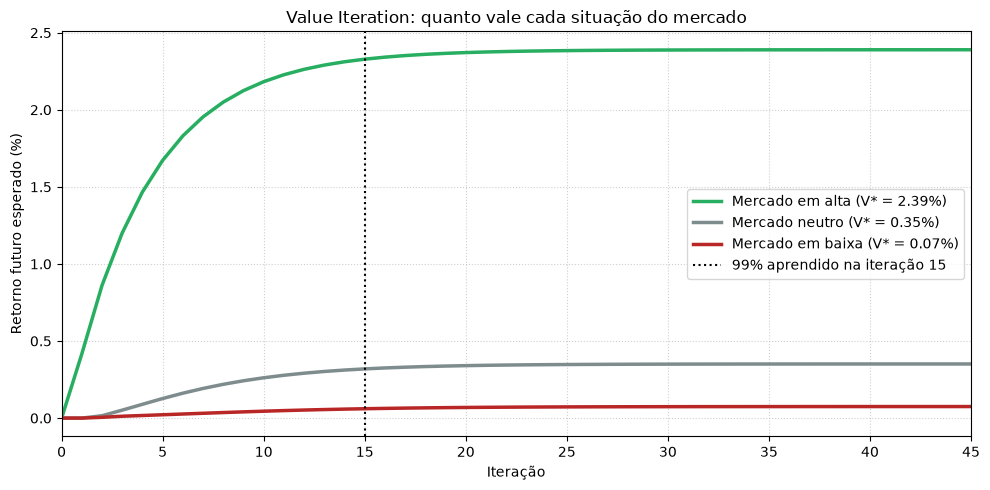

99% do valor ótimo na iteração 15; convergência total em 98 iterações


In [ ]:
regimes = {"Mercado em alta": (2, "#27AE60"), "Mercado neutro": (1, "#7F8C8D"), "Mercado em baixa": (0, "#B92626")}
aprendido = 1 - np.abs(historico - V_star).max(axis=1) / np.abs(V_star).max()
k_bom = np.argmax(aprendido >= 0.99)   # iteração em que o robô já sabe 99% do valor ótimo

fig, ax = plt.subplots(figsize=(10, 5))
for nome, (b, cor) in regimes.items():
    s = idx(b, b, 0)   # regime estável, robô fora do mercado
    ax.plot(100 * historico[:, s], lw=2.5, color=cor, label=f"{nome} (V* = {100 * V_star[s]:.2f}%)")
ax.axvline(k_bom, color="black", ls=":", label=f"99% aprendido na iteração {k_bom}")
ax.set(title="Value Iteration: quanto vale cada situação do mercado",
       xlabel="Iteração", ylabel="Retorno futuro esperado (%)", xlim=(0, 3 * k_bom))
ax.grid(True, ls=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig("curva_value_iteration.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"99% do valor ótimo na iteração {k_bom}; convergência total em {len(historico) - 1} iterações")

## 7. Testes do modelo

In [ ]:
resultados_testes = []

def teste(nome, cond):
    print("✅" if cond else "❌", nome)
    resultados_testes.append(bool(cond))

teste("Sem NaN nas séries", not df[["rho", "x", "b", "feature_b_t", "feature_b_tm1"]].isna().any().any())
teste("Treino termina antes do teste", df_treino.index.max() < df_teste.index.min())
teste("feature_b_tm1 é o b defasado", (df["feature_b_tm1"].values[1:] == df["b"].values[:-1]).all())
teste("27 estados com índices únicos 0..26", sorted(idx(*s) for s in ESTADOS) == list(range(nS)))
teste("Cada linha de P̂(·|s,a) soma 1", np.allclose(P_hat.sum(axis=2), 1))
teste("Transição determinística: φ_t vira o lag e h_t = a_t",
      all(P_hat[idx(*s), ia, idx(*s2)] == 0
          for s in ESTADOS for ia, a in enumerate(ACOES) for s2 in ESTADOS
          if s2[1] != s[0] or s2[2] != a))
teste("Neutro mantido (a = h = 0) tem recompensa zero", np.allclose(R_hat[idx(1, 1, 0), 1], 0))

Q_check = np.einsum("sat,sat->sa", P_hat, R_hat + GAMMA * V_star)
teste("V* é ponto fixo de Bellman (resíduo < 1e-8)", np.abs(Q_check.max(axis=1) - V_star).max() < 1e-8)
teste("π* é gulosa em relação a Q*", (Q_check.argmax(axis=1) == pi_star).all())

print(f"\n{sum(resultados_testes)}/{len(resultados_testes)} testes passaram")
assert all(resultados_testes), "Algum teste falhou"

✅ Sem NaN nas séries
✅ Treino termina antes do teste
✅ feature_b_tm1 é o b defasado
✅ 27 estados com índices únicos 0..26
✅ Cada linha de P̂(·|s,a) soma 1
✅ Transição determinística: φ_t vira o lag e h_t = a_t
✅ Neutro mantido (a = h = 0) tem recompensa zero
✅ V* é ponto fixo de Bellman (resíduo < 1e-8)
✅ π* é gulosa em relação a Q*

9/9 testes passaram


## 8. Políticas no `gym-trading-env`

In [ ]:
def criar_env(d):
    return TradingEnv(df=d, name=TICKER, positions=ACOES, initial_position=0,
                      trading_fees=KAPPA, borrow_interest_rate=0,
                      portfolio_initial_value=1000, verbose=0)

def rodar_no_ambiente(d, politica, epsilon=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    env = criar_env(d)
    obs, info = env.reset(seed=seed)
    h = 0
    valores, recompensas, acoes = [info["portfolio_valuation"]], [], []
    for _ in range(len(d) - 1):
        a = politica(int(obs[0]), int(obs[1]), h)
        if rng.random() < epsilon:   # ε-greedy
            a = int(rng.choice(ACOES))
        obs, r, done, truncated, info = env.step(ACOES.index(a))
        valores.append(info["portfolio_valuation"])
        recompensas.append(r)
        acoes.append(a)
        h = a
        if done or truncated:
            break
    env.close()
    return pd.Series(valores, index=d.index[:len(valores)]), np.array(recompensas), np.array(acoes)

def metricas(valores, acoes):
    lr = np.log(valores).diff().dropna()
    ex = lr - df["rf"].loc[lr.index]   # retorno em excesso à taxa livre
    tot = valores.iloc[-1] / valores.iloc[0]
    return {
        "Patrimônio final": valores.iloc[-1],
        "Retorno total": tot - 1,
        "Retorno anual": tot ** (PERIODOS_ANO / len(lr)) - 1,
        "Sharpe": ex.mean() / ex.std() * np.sqrt(PERIODOS_ANO) if lr.std() > 0 else 0.0,
        "Max drawdown": (valores / valores.cummax() - 1).min(),
        "Nº de trocas": int((np.diff(acoes, prepend=0) != 0).sum()),
    }

politicas = {   # nome: (política, ε)
    "MDP (Value Iteration)": (lambda b0, b1, h: ACOES[pi_star[idx(b0, b1, h)]], 0.0),
    "Buy & Hold":            (lambda b0, b1, h: 1, 0.0),
    "Fora do mercado":       (lambda b0, b1, h: 0, 0.0),
    "Aleatória":             (lambda b0, b1, h: 0, 1.0),
}

resultados, curvas = {}, {}
for conjunto, dados in [("Treino", df_treino), ("Teste", df_teste)]:
    for nome, (pol, eps) in politicas.items():
        v, r, a = rodar_no_ambiente(dados, pol, epsilon=eps)
        resultados[(conjunto, nome)] = metricas(v, a)
        curvas[(conjunto, nome)] = (v, r, a)

display(pd.DataFrame(resultados).T.style.format({
    "Patrimônio final": "US$ {:,.2f}", "Retorno total": "{:.2%}", "Retorno anual": "{:.2%}", "Sharpe": "{:.2f}",
    "Max drawdown": "{:.2%}", "Nº de trocas": "{:.0f}",
}))

## 9. Testes do ambiente

In [ ]:
c = df_teste["close"].values
v_mdp, r_env, a_mdp = curvas[("Teste", "MDP (Value Iteration)")]
v_fora = curvas[("Teste", "Fora do mercado")][0]
v_bh = curvas[("Teste", "Buy & Hold")][0]

obs, _ = criar_env(df_teste).reset(seed=SEED)
teste("Observação inicial = [φ(x_t), φ(x_t-1)] da 1ª linha do teste",
      obs[0] == df_teste["feature_b_t"].iloc[0] and obs[1] == df_teste["feature_b_tm1"].iloc[0])
teste(f"Episódio cobre o teste inteiro ({len(a_mdp)} de {len(df_teste) - 1} passos)",
      len(a_mdp) >= len(df_teste) - 2)
teste("Fora do mercado mantém o patrimônio em 1000", np.allclose(v_fora, 1000))

erro_bh = abs(v_bh.iloc[-1] / (1000 * (1 - KAPPA) * c[len(v_bh) - 1] / c[0]) - 1)
teste(f"Buy & Hold acompanha o preço (erro {erro_bh:.3%})", erro_bh < 0.01)

n = len(a_mdp)
h_prev = np.concatenate([[0], a_mdp[:-1]])
R_formula = np.log(1 + a_mdp * (c[1:n + 1] / c[:n] - 1) - KAPPA * np.abs(a_mdp - h_prev))
diff = np.abs(r_env - R_formula)
short_mantido = (a_mdp == -1) & (h_prev == -1)
print(f"|R_env - R_fórmula| médio: {diff[~short_mantido].mean():.2e} "
      f"| em short mantido: {diff[short_mantido].mean():.2e} ({short_mantido.sum()} passos)")
# No short o ambiente mantém fixa a quantidade vendida (não rebalanceia para -100%),
# por isso pequenas diferenças nesses passos são esperadas.
teste("Recompensa do ambiente = ln(1 + a·r - κ|a - h|) fora de short mantido",
      diff[~short_mantido].mean() < 1e-4)

✅ Observação inicial = [φ(x_t), φ(x_t-1)] da 1ª linha do teste
✅ Episódio cobre o teste inteiro (1771 de 1771 passos)
✅ Fora do mercado mantém o patrimônio em 1000
✅ Buy & Hold acompanha o preço (erro 0.000%)
|R_env - R_fórmula| médio: 1.42e-06 | em short mantido: 4.23e-04 (15 passos)
✅ Recompensa do ambiente = ln(1 + a·r - κ|a - h|) fora de short mantido


## 10. Gráficos do teste

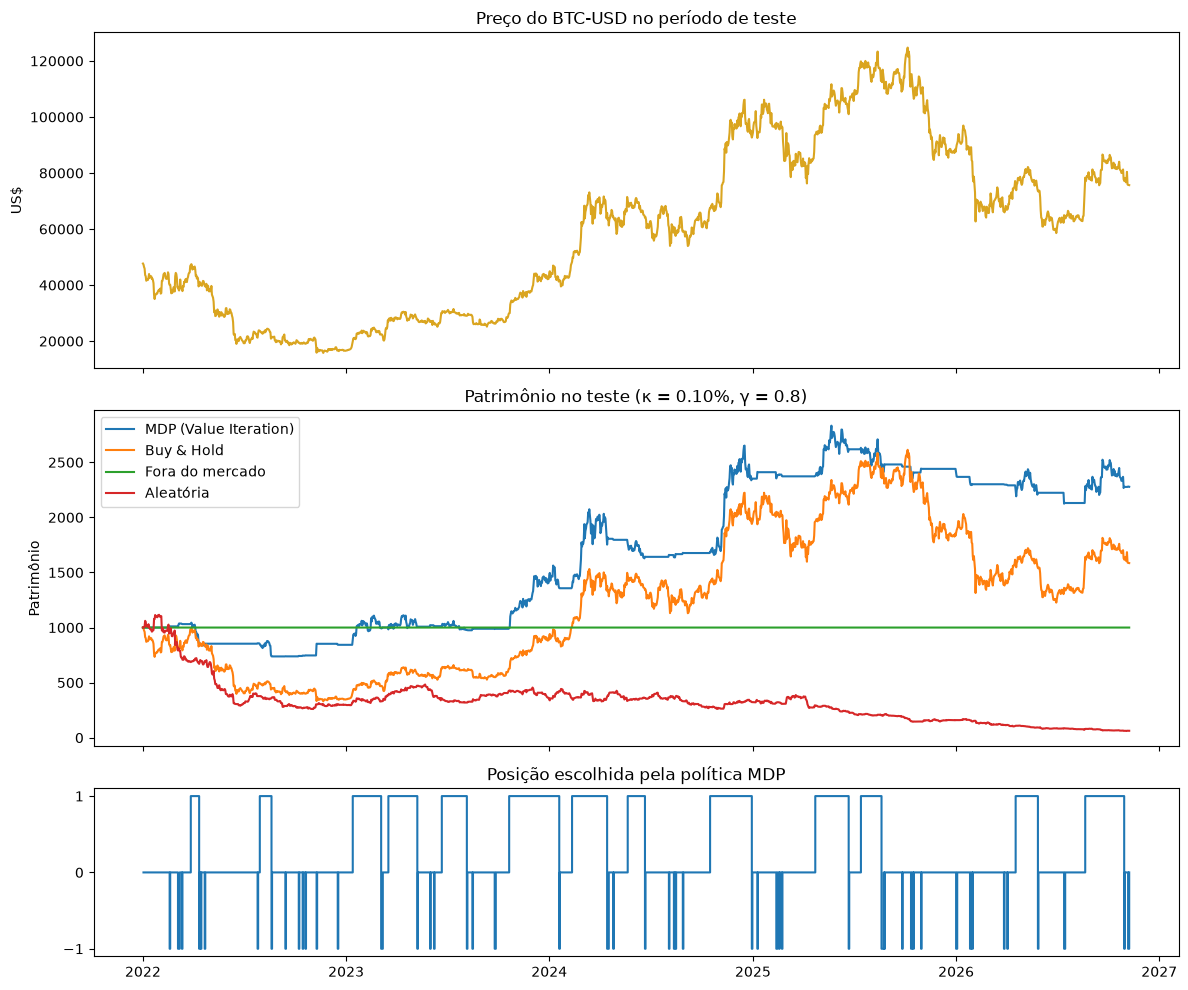

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})

ax[0].plot(df_teste.index, df_teste["close"], color="goldenrod")
ax[0].set(title=f"Preço do {TICKER} no período de teste", ylabel="US$")

for nome in politicas:
    v = curvas[("Teste", nome)][0]
    ax[1].plot(v.index, v.values, label=nome)
ax[1].set(title=f"Patrimônio no teste (κ = {KAPPA:.2%}, γ = {GAMMA})", ylabel="Patrimônio")
ax[1].legend()

ax[2].step(v_mdp.index[1:len(a_mdp) + 1], a_mdp, where="post")
ax[2].set(title="Posição escolhida pela política MDP", yticks=[-1, 0, 1])

plt.tight_layout()
plt.show()

## 11. Benchmark: MDP vs. modelos supervisionados

In [ ]:
def preparar_features(d):
    d = d.copy()
    d["rho_fwd"] = d["rho"].shift(-1)
    d["alvo"] = np.sign(d["rho_fwd"]).replace(0, 1)
    d["vol_20"] = d["rho"].rolling(20).std()
    d["rho_lag1"] = d["rho"]
    d["rho_lag2"] = d["rho"].shift(1)
    return d.dropna()

tr, te = preparar_features(df_treino), preparar_features(df_teste)
FEATS = ["x", "vol_20", "rho_lag1", "rho_lag2"]
X_tr, y_tr, X_te = tr[FEATS], tr["alvo"], te[FEATS]

def zona_morta(p):   # compra se P(alta) > 53%, vende se < 47%, senão neutro
    return np.where(p > 0.53, 1, np.where(p < 0.47, -1, 0))

def posicoes_mdp(d):
    h, pos = 0, []
    for b0, b1 in zip(d["b"], d["feature_b_tm1"].astype(int)):
        h = ACOES[pi_star[idx(b0, b1, h)]]
        pos.append(h)
    return pos

pos = pd.DataFrame(index=te.index)
pos["MDP (Value Iteration)"] = posicoes_mdp(te)
pos["Buy & Hold"] = 1
pos["Heurística Preço/MA50"] = np.where(te["x"] > 0, 1, -1)
pos["Regressão Linear (OLS)"] = np.where(te["x"] > 0, 1, -1)
lasso = Lasso(alpha=0.0001, random_state=SEED).fit(X_tr, tr["rho_fwd"])
pos["Regressão Lasso (L1)"] = np.where(lasso.predict(X_te) > 0, 1, -1)

classificadores = {   # nome: (modelo, usa zona morta sobre a probabilidade)
    "Classificador Ridge (L2)":     (RidgeClassifier(alpha=1.0, random_state=SEED), False),
    "Regressão Logística (Filtro)": (LogisticRegression(random_state=SEED), True),
    "Árvore de Decisão (Cart)":     (DecisionTreeClassifier(max_depth=3, random_state=SEED), False),
    "Random Forest":                (RandomForestClassifier(n_estimators=50, max_depth=3, random_state=SEED), True),
    "Gradient Boosting":            (HistGradientBoostingClassifier(max_depth=3, random_state=SEED), False),
    "Support Vector Machine (SVM)": (LinearSVC(random_state=SEED, max_iter=2000), False),
    "K-Nearest Neighbors (KNN)":    (KNeighborsClassifier(n_neighbors=15), False),
}
for nome, (modelo, usa_prob) in classificadores.items():
    modelo.fit(X_tr, y_tr)
    pos[nome] = zona_morta(modelo.predict_proba(X_te)[:, 1]) if usa_prob else modelo.predict(X_te)

r_fwd = te["close"].pct_change().shift(-1)

def simular(p):
    p = np.asarray(p, dtype=float)
    h = np.concatenate([[0.0], p[:-1]])
    lr = np.log(np.maximum(1 + p * r_fwd - KAPPA * np.abs(p - h), 1e-12))
    return 1000 * np.exp(lr.fillna(0).cumsum().shift(fill_value=0)), lr, int((p != h).sum())   # começa em US$ 1.000

linhas, df_curvas = {}, pd.DataFrame(index=te.index)
for nome in pos:
    curva, lr, trocas = simular(pos[nome])
    df_curvas[nome] = curva
    tot = curva.iloc[-1] / curva.iloc[0] - 1
    linhas[nome] = {
        "Patrimônio Final": curva.iloc[-1],
        "Retorno Total": tot,
        "Retorno Anual": (1 + tot) ** (PERIODOS_ANO / lr.count()) - 1,
        "Índice Sharpe": (lr - te["rf"]).mean() / (lr - te["rf"]).std() * np.sqrt(PERIODOS_ANO),
        "Max Drawdown": (curva / curva.cummax() - 1).min(),
        "Turnover (Trocas)": trocas,
    }

df_ranking = pd.DataFrame(linhas).T.sort_values("Índice Sharpe", ascending=False)
display(df_ranking.style.format({
    "Patrimônio Final": "US$ {:,.2f}", "Retorno Total": "{:+.2%}", "Retorno Anual": "{:+.2%}", "Índice Sharpe": "{:.2f}",
    "Max Drawdown": "{:.2%}", "Turnover (Trocas)": "{:.0f}",
}))

,Patrimônio Final,Retorno Total,Retorno Anual,Índice Sharpe,Max Drawdown,Turnover (Trocas)
MDP (Value Iteration),"US$ 2,270.84",+127.08%,+18.64%,0.46,-29.35%,113
Support Vector Machine (SVM),"US$ 2,763.50",+176.35%,+23.60%,0.34,-62.59%,93
Classificador Ridge (L2),"US$ 2,668.71",+166.87%,+22.71%,0.33,-62.28%,69
Buy & Hold,"US$ 1,859.92",+85.99%,+13.81%,0.18,-66.74%,1
Regressão Lasso (L1),"US$ 1,859.92",+85.99%,+13.81%,0.18,-66.74%,1
Heurística Preço/MA50,"US$ 1,746.84",+74.68%,+12.33%,0.15,-62.13%,105
Regressão Linear (OLS),"US$ 1,746.84",+74.68%,+12.33%,0.15,-62.13%,105
Regressão Logística (Filtro),"US$ 1,635.97",+63.60%,+10.81%,0.14,-62.22%,257
Random Forest,"US$ 1,335.98",+33.60%,+6.22%,0.05,-53.58%,600
Árvore de Decisão (Cart),US$ 383.76,-61.62%,-18.10%,-0.47,-70.39%,611


## 12. Risco x retorno e Sharpe

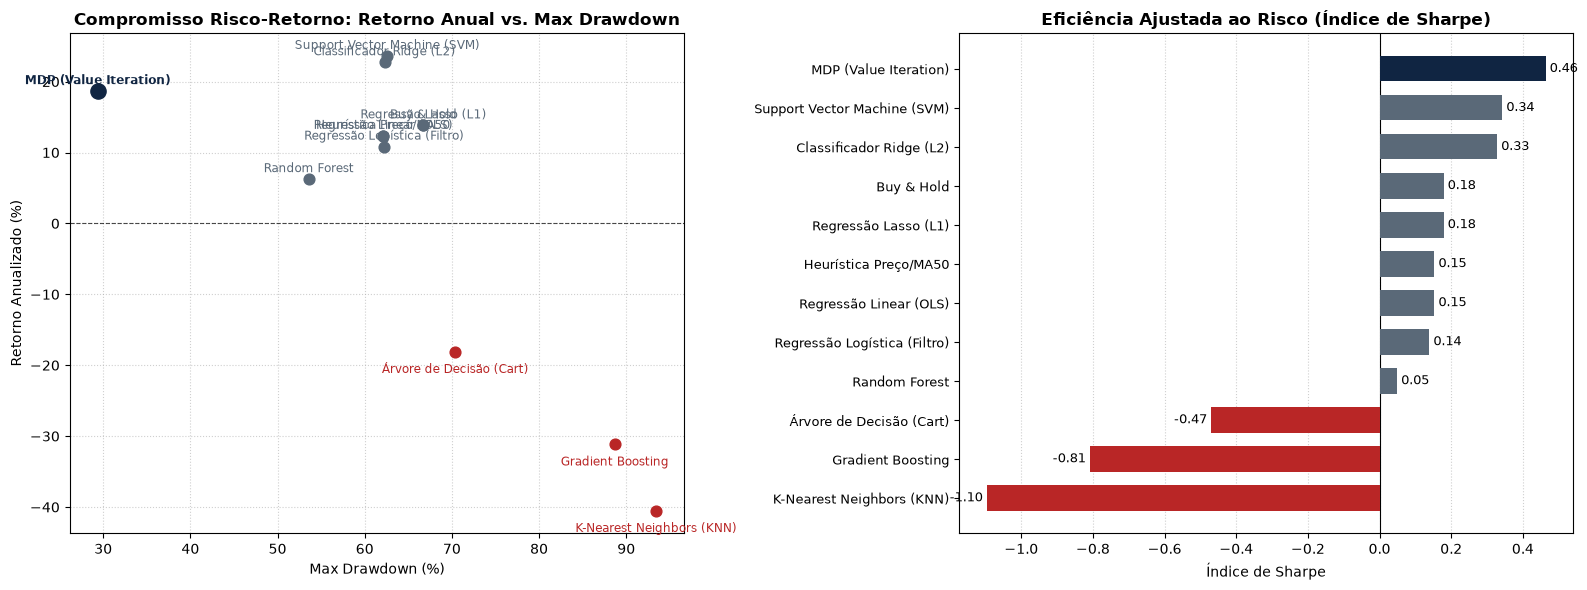

In [ ]:
nomes = df_ranking.index
sharpes = df_ranking["Índice Sharpe"].values
ret_anual = df_ranking["Retorno Anual"].values * 100
drawdowns = -df_ranking["Max Drawdown"].values * 100
cores = ["#102542" if "MDP" in n else "#5A6978" if s > 0 else "#B92626" for n, s in zip(nomes, sharpes)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for nome, x, y, cor in zip(nomes, drawdowns, ret_anual, cores):
    mdp = "MDP" in nome
    ax1.scatter(x, y, color=cor, s=120 if mdp else 60, zorder=3)
    ax1.annotate(nome, (x, y + (1 if y >= 0 else -3)), fontsize=8.5, ha="center",
                 color=cor, weight="bold" if mdp else "normal")
ax1.axhline(0, color="black", ls="--", lw=0.8, alpha=0.7)
ax1.set_title("Compromisso Risco-Retorno: Retorno Anual vs. Max Drawdown", fontsize=12, fontweight="bold")
ax1.set(xlabel="Max Drawdown (%)", ylabel="Retorno Anualizado (%)")
ax1.grid(True, ls=":", alpha=0.6)

y = np.arange(len(nomes))
barras = ax2.barh(y, sharpes, color=cores, height=0.65, zorder=3)
ax2.bar_label(barras, fmt="%.2f", padding=3, fontsize=9)
ax2.set_yticks(y, nomes, fontsize=9)
ax2.invert_yaxis()
ax2.axvline(0, color="black", lw=0.8)
ax2.set_title("Eficiência Ajustada ao Risco (Índice de Sharpe)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Índice de Sharpe")
ax2.grid(True, axis="x", ls=":", alpha=0.6)

plt.tight_layout()
plt.savefig("benchmark_modelos.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Curva de capital no teste

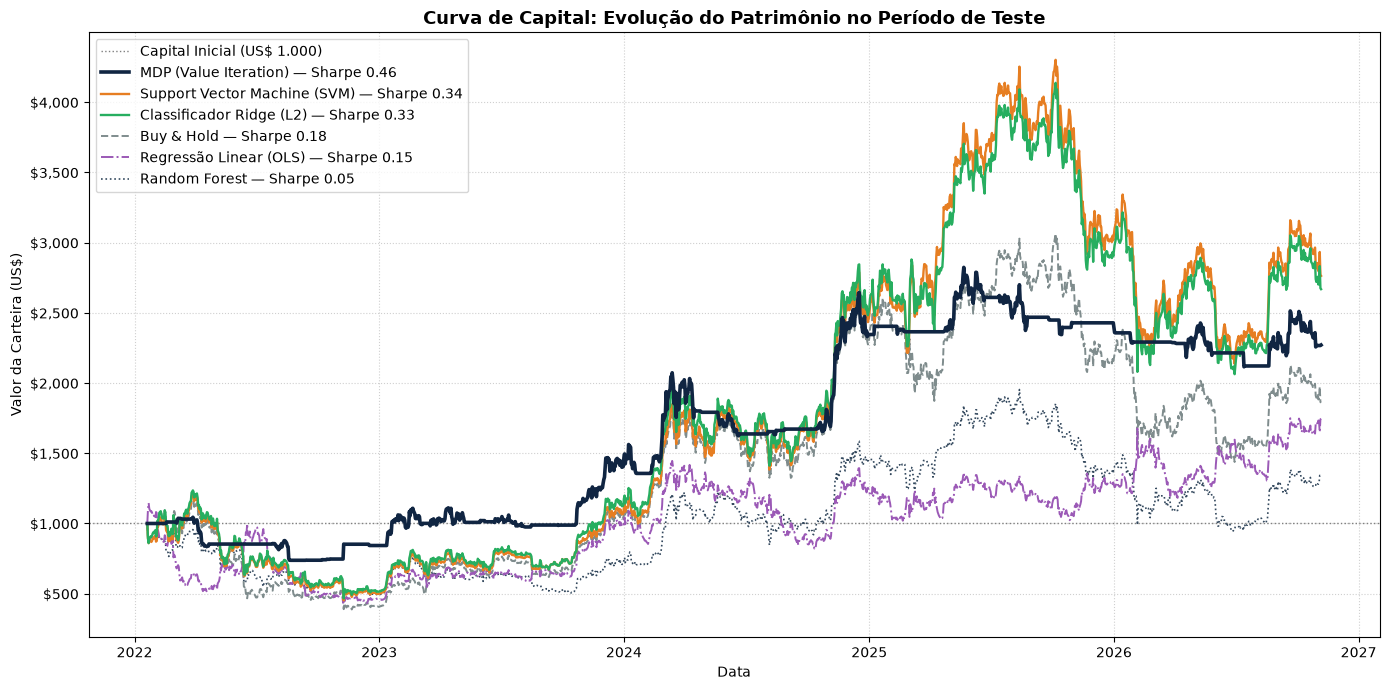

In [ ]:
destaques = {
    "MDP (Value Iteration)":        dict(color="#102542", lw=2.6, zorder=5),
    "Support Vector Machine (SVM)": dict(color="#E67E22", lw=1.7, zorder=4),
    "Classificador Ridge (L2)":     dict(color="#27AE60", lw=1.7, zorder=4),
    "Buy & Hold":                   dict(color="#7F8C8D", lw=1.4, ls="--", zorder=3),
    "Regressão Linear (OLS)":       dict(color="#9B59B6", lw=1.4, ls="-.", zorder=3),
    "Random Forest":                dict(color="#34495E", lw=1.2, ls=":", zorder=2),
}

fig, ax = plt.subplots(figsize=(14, 7))
ax.axhline(1000, color="gray", ls=":", lw=1, label="Capital Inicial (US$ 1.000)")
for nome, estilo in destaques.items():
    sharpe = df_ranking.loc[nome, "Índice Sharpe"]
    ax.plot(df_curvas.index, df_curvas[nome], label=f"{nome} — Sharpe {sharpe:.2f}", **estilo)

ax.set_title("Curva de Capital: Evolução do Patrimônio no Período de Teste", fontsize=13, fontweight="bold")
ax.set(xlabel="Data", ylabel="Valor da Carteira (US$)")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.grid(True, ls=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.savefig("curva_patrimonio.png", dpi=300, bbox_inches="tight")
plt.show()